# Paper-method benchmarks on the neural-only example data

This notebook uses the same seed, CPU data generator, sample size, censoring target (`q=0.2` by default), 80/20 split, and 256-point survival grid as `model_mlp.ipynb`. Each eligible paper method is fitted to the **same generated tensors**, and the reported test metric is the same Average `grid_sse`:

```python
(estimated_survival - true_survival).square().sum(dim=1).mean()
```

Set `SCENARIO` to `ph`, `lognormal`, `po`, or `multimodal`. The multimodal reference curve marginalizes over the latent component. AFT uses exponential for PH (Weibull shape one), lognormal for lognormal, log-logistic for PO, and a single Weibull working model for the mixture. These correspond to minimum extreme-value, Gaussian, and logistic errors on log time. Error scales are estimated for lognormal, PO, and Weibull; the exponential scale on log time is fixed at one. The covariate predictor remains linear in the supplied covariates. Cox and AFT accept all four observation schemes; DeepSurv accepts exact and right-censored data only. The original paper-method restrictions for the other benchmarks remain unchanged.

The notebook selects exactly one DeepSurv backend: when CUDA is available it runs only **DeepSurv (PyTorch CUDA)**; otherwise it falls back to **DeepSurv (official CPU)**. The CUDA path keeps the same architecture, loss, optimizer settings, and fixed `PAPER_GAUSSIAN_PARAMETERS` settings while changing only tensor execution. If `DEEPSURV_CUDA_TUNE=True`, the unchanged published search also runs every cross-validation fit on CUDA. Exact observations use `e=1`; right-censored observations use `e=0`.

The generator is `testdata2.py`: all six covariates are independent Uniform(-1, 1). Set `SCENARIO` to `ph`, `lognormal`, `po`, or `multimodal`, and `CENSOR_Q` to `0.2` or `0.5`. The multimodal distribution has two equal-weight Weibull components with shapes `(5, 8)` and baseline scales `(0.5, 3)` for `MULTIMODAL_CASE="separate"` or `(0.5, 1.8)` for `MULTIMODAL_CASE="closer"`. See `testdata2.md` for the formulas and censoring process.

In [ ]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "tuning" / "testdata2.py").is_file() and (path / "testing").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the NRT project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from testing.benchmark.aft import (
    ParametricAFT, distribution_for_scenario,
    r_backend_available as aft_backend_available,
)
from testing.benchmark.cox import (
    CoxPH, r_backend_available as cox_backend_available,
)
from testing.benchmark.ctree import (
    CTree, r_backend_available as ctree_backend_available,
)
from testing.benchmark.deep_distribution_regression import (
    DeepDistributionRegression,
)
from testing.benchmark.deepsurv import (
    DeepSurv, DeepSurvCUDA, PAPER_GAUSSIAN_PARAMETERS,
    backend_available as deepsurv_backend_available,
)
from testing.benchmark.iccforest import ICCForest, r_backend_available
from testing.benchmark.nncde import NNCDE
import importlib
import testing.testdata2 as simulation_data
importlib.reload(simulation_data)  # pick up generator changes on rerun
from testing.testdata2 import (
    MULTIMODAL_SCALE_MULTIPLIER_CASES,
    MULTIMODAL_SHAPES,
    survival_curves,
    multimodal_survival,
    data_reg,
    data_reg_multimodal,
)

SEED = 123
N_SAMPLES = 5000
X_DIM = 6
CENSOR_Q = 0.2  # 0.2: moderate; 0.5: high right censoring
GRID_SIZE = 256
SCENARIO = "po"  # ph, lognormal, po, or multimodal
CENSOR_TYPE = "right"  # exact, right, interval, or current
MULTIMODAL_CASE = "separate"  # separate or closer peaks
SCALE_MULTIPLIERS = MULTIMODAL_SCALE_MULTIPLIER_CASES[MULTIMODAL_CASE]
DATA_DEVICE = torch.device("cpu")  # guarantees identical generated tensors
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEEPSURV_CUDA_TUNE = False  # True runs the unchanged published search
DEEPSURV_TUNING_EVALUATIONS = 50
DEEPSURV_TUNING_FOLDS = 3
DEEPSURV_TUNING_EPOCHS = 500
torch.manual_seed(SEED)
run_description = f"Device: {DEVICE}; scenario: {SCENARIO}; censoring: {CENSOR_TYPE}"
if SCENARIO == "multimodal":
    run_description += f"; multimodal case: {MULTIMODAL_CASE}; scale multipliers: {SCALE_MULTIPLIERS}; component shapes: {MULTIMODAL_SHAPES}"
print(run_description)

## Generate the shared example data

The following cell intentionally matches the data cell in `model_mlp.ipynb`. It resets the seed immediately before generating on CPU, so rerunning other cells does not change the sample and every eligible benchmark receives identical training and test observations.

Training rows: 4000; test rows: 1000
max_bound: 12.423435; grid points: 256


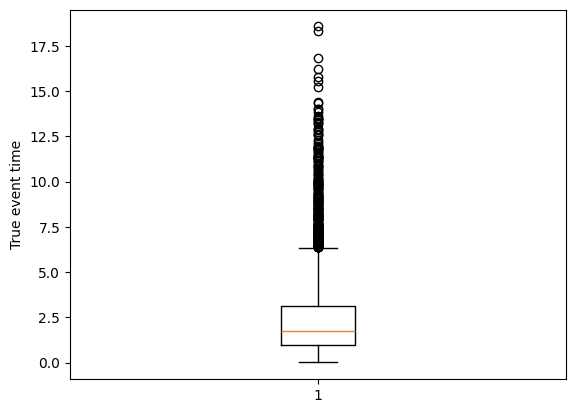

In [35]:
torch.manual_seed(SEED)
data_kwargs = dict(
    n=N_SAMPLES, x_dim=X_DIM, q=CENSOR_Q,
    censor_type=CENSOR_TYPE, device=DATA_DEVICE,
)
if SCENARIO == "multimodal":
    x, L, R, event_time, mixture_weights, component_scales, component = (
        data_reg_multimodal(**data_kwargs, multimodal_case=MULTIMODAL_CASE)
    )
else:
    x, L, R, event_time, shape, scale = data_reg(**data_kwargs, scenario=SCENARIO)
n_train = int(0.8 * len(x))
x_train, x_test = x[:n_train], x[n_train:]
L_train, L_test = L[:n_train], L[n_train:]
R_train, R_test = R[:n_train], R[n_train:]
finite_bounds = torch.cat(
    (L_train[torch.isfinite(L_train)], R_train[torch.isfinite(R_train)])
)
max_obs = finite_bounds.max().item()
max_bound = 1.1 * max_obs
grid = torch.linspace(0.0, max_obs, GRID_SIZE, device=DATA_DEVICE)
if SCENARIO == "multimodal":
    true_survival = multimodal_survival(mixture_weights[n_train:], component_scales[n_train:], grid)
else:
    shape_test, scale_test = shape[n_train:], scale[n_train:]
    true_survival = survival_curves(shape_test, scale_test, grid, scenario=SCENARIO)

print(f"Training rows: {n_train}; test rows: {len(x_test)}")
print(f"max_bound: {max_bound:.6f}; grid points: {grid.numel()}")
# Verify the NumPy module used by Matplotlib before creating a figure.
import numpy as np
try:
    np.unique([0, 0, 1])
    np.percentile([0.0, 1.0], [25, 50, 75])
except AttributeError as exc:
    raise RuntimeError(
        "The notebook kernel has an incomplete NumPy module. "
        "Select Restart Kernel, select the PolyaPFN environment, then Run All. "
        f"Python: {sys.executable}; NumPy: {getattr(np, '__file__', 'unknown')}"
    ) from exc

plt.boxplot(event_time.detach().cpu().numpy().reshape(-1))
plt.ylabel("True event time")
plt.show()

## Configure the paper methods

These defaults follow the implementations documented in `benchmark/README.md`. The neural methods can take time on all 4096 observations; reduce `epochs` only when doing a quick smoke test.

In [ ]:
methods = {
    "Cox PH": CoxPH(),
    "AFT": ParametricAFT(
        distribution=distribution_for_scenario(SCENARIO),
    ),
    "ICcforest": ICCForest(
        ntree=100, tune_mtry=False, tune_ntree=100
    ),
    "ctree": CTree(
        mincriterion=0.95, minsplit=20, minbucket=7, seed=SEED
    ),
    "NNCDE": NNCDE(
        hidden_nodes=128 , learning_rate=1e-3, batch_size=256,
        epochs=200, patience=20, seed=SEED, device=DEVICE,
    ),
    "Deep Distribution Regression": DeepDistributionRegression(
        cut_fraction=0.10, hidden_nodes=100, dropout=0.5,
        learning_rate=1e-3, batch_size=256, epochs=500,
        patience=20, seed=SEED, device=DEVICE,
    ),
}
if torch.cuda.is_available():
    methods["DeepSurv (PyTorch CUDA)"] = DeepSurvCUDA(
        **PAPER_GAUSSIAN_PARAMETERS, seed=SEED, device="cuda", tune=DEEPSURV_CUDA_TUNE,
        tuning_evals=DEEPSURV_TUNING_EVALUATIONS,
        cv_folds=DEEPSURV_TUNING_FOLDS,
        tuning_epochs=DEEPSURV_TUNING_EPOCHS,
    )
else:
    methods["DeepSurv (official CPU)"] = DeepSurv(
        seed=SEED, device="cpu", tune=False,
    )

for name, method in methods.items():
    if name.startswith("DeepSurv"):
        print(f'{name} modeling parameters:', method.modeling_parameters)
        print(f'{name} tuning policy:', method.tuning_parameters)

for name, method in methods.items():
    status = ("eligible" if CENSOR_TYPE in method.supported_censor_types
              else "skipped: unsupported by the paper method")
    if name == "ICcforest" and status == "eligible" and not r_backend_available():
        status = "skipped: R/ICcforest backend unavailable"
    if name == "ctree" and status == "eligible" and not ctree_backend_available():
        status = "skipped: R/partykit backend unavailable"
    if name == "Cox PH" and status == "eligible" and not cox_backend_available():
        status = "skipped: R survival/icenReg backend unavailable"
    if name == "AFT" and status == "eligible" and not aft_backend_available():
        status = "skipped: R survival backend unavailable"
    if name == "DeepSurv (official CPU)" and status == "eligible" and not deepsurv_backend_available():
        status = "skipped: official Theano/Lasagne backend unavailable"
    print(f"{name}: {status}")

## Fit and calculate Average `grid_sse`

Unsupported method/data combinations are recorded rather than coercing censoring intervals into exact outcomes.

In [37]:
results = []
estimated_curves = {}

for name, method in methods.items():
    if CENSOR_TYPE not in method.supported_censor_types:
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "unsupported",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue
    if name == "ICcforest" and not r_backend_available():
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "R backend unavailable",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue
    if name == "ctree" and not ctree_backend_available():
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "R backend unavailable",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue
    if name == "Cox PH" and not cox_backend_available():
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "R survival/icenReg unavailable",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue
    if name == "AFT" and not aft_backend_available():
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "R survival unavailable",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue
    if name == "DeepSurv (official CPU)" and not deepsurv_backend_available():
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE,
            "status": "official DeepSurv backend unavailable",
            "average_grid_sse": float("nan"), "runtime_seconds": 0.0,
        })
        continue

    print(f"Fitting {name}...")
    started = time.perf_counter()
    try:
        method.fit(x_train, L_train, R_train, censor_type=CENSOR_TYPE)
        estimated = method.predict_survival(x_test, grid)
        score = (estimated - true_survival.to(estimated.device)).square().sum(dim=1).mean().item()
        estimated_curves[name] = estimated.detach().cpu()
        results.append({
            "method": name, "scenario": SCENARIO,
            "multimodal_case": MULTIMODAL_CASE if SCENARIO == "multimodal" else None,
            "scale_multipliers": SCALE_MULTIPLIERS if SCENARIO == "multimodal" else None,
            "component_shapes": MULTIMODAL_SHAPES if SCENARIO == "multimodal" else None,
            "censor_type": CENSOR_TYPE, "status": "completed",
            "average_grid_sse": score,
            "runtime_seconds": time.perf_counter() - started,
        })
        print(f"{name} Average grid_sse: {score:.6f}")
    finally:
        if hasattr(method, "close"):
            method.close()

results_df = pd.DataFrame(results)
results_df

Fitting Cox PH...
Cox PH Average grid_sse: 2.459189
Fitting AFT...
AFT Average grid_sse: 2.493509
Fitting ICcforest...
ICcforest Average grid_sse: 1.558938
Fitting ctree...
ctree Average grid_sse: 2.434220
Fitting NNCDE...
NNCDE Average grid_sse: 0.298596
Fitting DeepSurv (PyTorch CUDA)...
DeepSurv (PyTorch CUDA) Average grid_sse: 0.339333


,method,scenario,multimodal_case,scale_multipliers,component_shapes,censor_type,status,average_grid_sse,runtime_seconds
0,Cox PH,po,None,None,None,right,completed,2.459189,2.128984
1,AFT,po,None,None,None,right,completed,2.493509,1.844329
2,ICcforest,po,None,None,None,right,completed,1.558938,49.770563
3,ctree,po,None,None,None,right,completed,2.434220,2.876249
4,NNCDE,po,None,None,None,right,completed,0.298596,13.111797
5,Deep Distribution Regression,po,None,None,None,right,unsupported,NaN,0.000000
6,DeepSurv (PyTorch CUDA),po,None,None,None,right,completed,0.339333,2.967531


In [38]:
model = methods["DeepSurv (PyTorch CUDA)"]

print("Parameters:")
print(model.modeling_parameters)

print("Best parameters:")
print(model.best_hyperparameters_)

print("Best cross-validated C-index:")
print(model.best_validation_c_index_)

Parameters:
{'implementation': 'PyTorch CUDA reproduction of jaredleekatzman/DeepSurv@41eed003e5b892c81e7855e400861fa7a2d9da4f', 'device': 'cuda', 'hidden_layers': [39, 39, 39], 'learning_rate': 0.001485675043584323, 'lr_decay': 0.00024959960937500004, 'momentum': 0.93199267578125, 'l2_reg': 2.78821044921875, 'l1_reg': 0.0, 'activation': 'selu', 'dropout': 0.0735595703125, 'batch_norm': False, 'standardize': False, 'epochs': 1000, 'optimizer': 'full-batch ADAM', 'optimizer_semantics': 'constant learning rate; the pinned runner compiles its optimizer once and does not apply the later Python learning-rate and momentum rebindings', 'regularization_scope': 'final linear risk-layer weight', 'loss': 'negative Cox partial log-likelihood'}
Best parameters:
None
Best cross-validated C-index:
None


## Compare the same individual as `model_mlp.ipynb`

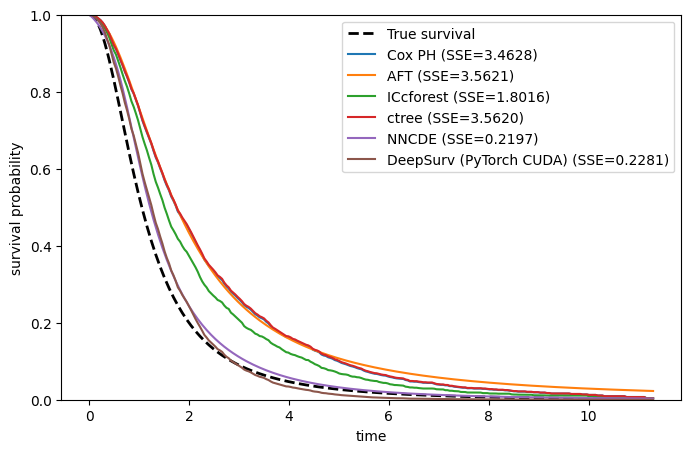

In [39]:
index = 0
individual_truth = true_survival[index].detach().cpu()
grid_cpu = grid.detach().cpu()
plt.figure(figsize=(8, 5))
plt.plot(grid_cpu, individual_truth, "k--", linewidth=2, label="True survival")
for name, curves in estimated_curves.items():
    individual_sse = (curves[index] - individual_truth).square().sum().item()
    plt.plot(grid_cpu, curves[index], label=f"{name} (SSE={individual_sse:.4f})")
plt.xlabel("time")
plt.ylabel("survival probability")
plt.ylim(0.0, 1.0)
plt.legend()
plt.show()